# Gene Expression Cancer RNA-Seq
## Dataset Exploration

### Introduction

This notebook explores the Gene Expression Cancer RNA-Seq dataset.

The dataset contains gene expression measurements from five
different cancer types.

### Objectives

- Understand the dataset structure.
- Explore samples and gene features.
- Inspect data types and statistical properties.
- Check missing values and duplicates.
- Analyze cancer type distribution.
- Prepare the dataset for Principal Component Analysis (PCA).

### 2 — Import Libraries

In [25]:
import os
import numpy as numpy
import pandas as pandas
import matplotlib.pyplot as matplotlib
import seaborn as seaborn

### 3 — Load Dataset

In [16]:
# Local dataset paths
data_path = "../data/data.csv"
labels_path = "../data/labels.csv"

# GitHub raw URLs
data_url = "https://media.githubusercontent.com/media/katibhakiim/Gene-Expression-Cancer-Dataset/main/data/data.csv"

labels_url = "https://media.githubusercontent.com/media/katibhakiim/Gene-Expression-Cancer-Dataset/main/data/labels.csv"

# Load dataset
if os.path.exists(data_path) and os.path.exists(labels_path):

    data = pandas.read_csv(data_path)
    labels = pandas.read_csv(labels_path)

    print("Dataset loaded from local files.")

else:

    data = pandas.read_csv(data_url)
    labels = pandas.read_csv(labels_url)

    print("Dataset loaded from GitHub.")

Dataset loaded from GitHub.


### 4 — Display Dataset Samples

In [26]:
print("Gene Expression Data:")
display(data.head())

print("Cancer Labels:")
display(labels.head())

Gene Expression Data:


,Unnamed: 0,gene_0,gene_1,gene_2,gene_3,gene_4,gene_5,gene_6,gene_7,gene_8,...,gene_20521,gene_20522,gene_20523,gene_20524,gene_20525,gene_20526,gene_20527,gene_20528,gene_20529,gene_20530
0,sample_0,0.0,2.017209,3.265527,5.478487,10.431999,0.0,7.175175,0.591871,0.0,...,4.926711,8.210257,9.723516,7.220030,9.119813,12.003135,9.650743,8.921326,5.286759,0.0
1,sample_1,0.0,0.592732,1.588421,7.586157,9.623011,0.0,6.816049,0.000000,0.0,...,4.593372,7.323865,9.740931,6.256586,8.381612,12.674552,10.517059,9.397854,2.094168,0.0
2,sample_2,0.0,3.511759,4.327199,6.881787,9.870730,0.0,6.972130,0.452595,0.0,...,5.125213,8.127123,10.908640,5.401607,9.911597,9.045255,9.788359,10.090470,1.683023,0.0
3,sample_3,0.0,3.663618,4.507649,6.659068,10.196184,0.0,7.843375,0.434882,0.0,...,6.076566,8.792959,10.141520,8.942805,9.601208,11.392682,9.694814,9.684365,3.292001,0.0
4,sample_4,0.0,2.655741,2.821547,6.539454,9.738265,0.0,6.566967,0.360982,0.0,...,5.996032,8.891425,10.373790,7.181162,9.846910,11.922439,9.217749,9.461191,5.110372,0.0


Cancer Labels:


,Unnamed: 0,Class
0,sample_0,PRAD
1,sample_1,LUAD
2,sample_2,PRAD
3,sample_3,PRAD
4,sample_4,BRCA


### 5 — Dataset Dimensions

In [27]:
print("Data Dimensions:", data.shape)
print("Labels Dimensions:", labels.shape)

print("Number of Samples:", data.shape[0])
print("Number of Data Columns:", data.shape[1])
print("Number of Label Rows:", labels.shape[0])

Data Dimensions: (801, 20532)
Labels Dimensions: (801, 2)
Number of Samples: 801
Number of Data Columns: 20532
Number of Label Rows: 801


### 6 — Dataset Information

In [32]:
print("Gene Expression Information:")
data.info()

print("\nLabels Information:")
labels.info()

Gene Expression Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 801 entries, 0 to 800
Columns: 20532 entries, Unnamed: 0 to gene_20530
dtypes: float64(20531), object(1)
memory usage: 125.5+ MB

Labels Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 801 entries, 0 to 800
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  801 non-null    object
 1   Class       801 non-null    object
dtypes: object(2)
memory usage: 12.6+ KB


### 7 — Statistical Description

In [29]:
display(data.describe())

,gene_0,gene_1,gene_2,gene_3,gene_4,gene_5,gene_6,gene_7,gene_8,gene_9,...,gene_20521,gene_20522,gene_20523,gene_20524,gene_20525,gene_20526,gene_20527,gene_20528,gene_20529,gene_20530
count,801.000000,801.000000,801.000000,801.000000,801.000000,801.0,801.000000,801.000000,801.000000,801.000000,...,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000
mean,0.026642,3.010909,3.095350,6.722305,9.813612,0.0,7.405509,0.499882,0.016744,0.013428,...,5.896573,8.765891,10.056252,4.847727,9.741987,11.742228,10.155271,9.590726,5.528177,0.095411
std,0.136850,1.200828,1.065601,0.638819,0.506537,0.0,1.108237,0.508799,0.133635,0.204722,...,0.746399,0.603176,0.379278,2.382728,0.533898,0.670371,0.580569,0.563849,2.073859,0.364529
min,0.000000,0.000000,0.000000,5.009284,8.435999,0.0,3.930747,0.000000,0.000000,0.000000,...,2.853517,6.678368,8.669456,0.000000,7.974942,9.045255,7.530141,7.864533,0.593975,0.000000
25%,0.000000,2.299039,2.390365,6.303346,9.464466,0.0,6.676042,0.000000,0.000000,0.000000,...,5.454926,8.383834,9.826027,3.130750,9.400747,11.315857,9.836525,9.244219,4.092385,0.000000
50%,0.000000,3.143687,3.127006,6.655893,9.791599,0.0,7.450114,0.443076,0.000000,0.000000,...,5.972582,8.784144,10.066385,5.444935,9.784524,11.749802,10.191207,9.566511,5.218618,0.000000
75%,0.000000,3.883484,3.802534,7.038447,10.142324,0.0,8.121984,0.789354,0.000000,0.000000,...,6.411292,9.147136,10.299025,6.637412,10.082269,12.177852,10.578561,9.917888,6.876382,0.000000
max,1.482332,6.237034,6.063484,10.129528,11.355621,0.0,10.718190,2.779008,1.785592,4.067604,...,7.771054,11.105431,11.318243,9.207495,11.811632,13.715361,11.675653,12.813320,11.205836,5.254133


### 8 — Missing Values

In [20]:
print("Missing values in data:")
print(data.isnull().sum().sum())

print("\nMissing values in labels:")
print(labels.isnull().sum().sum())

Missing values in data:
0

Missing values in labels:
0


### 9 — Duplicate Rows

In [21]:
print("Duplicate rows in data:", data.duplicated().sum())

print("Duplicate rows in labels:", labels.duplicated().sum())

Duplicate rows in data: 0
Duplicate rows in labels: 0


### Cell 10 — Explore Cancer Labels

In [22]:
print("Label Columns:")
print(labels.columns.tolist())

display(labels.value_counts())

Label Columns:
['Unnamed: 0', 'Class']


,,count
Unnamed: 0,Class,
sample_0,PRAD,1
sample_1,LUAD,1
sample_10,BRCA,1
sample_100,BRCA,1
sample_101,KIRC,1
...,...,...
sample_95,PRAD,1
sample_96,COAD,1
sample_97,BRCA,1


### 11 — Cancer Distribution

,count
Class,
BRCA,300
KIRC,146
LUAD,141
PRAD,136
COAD,78


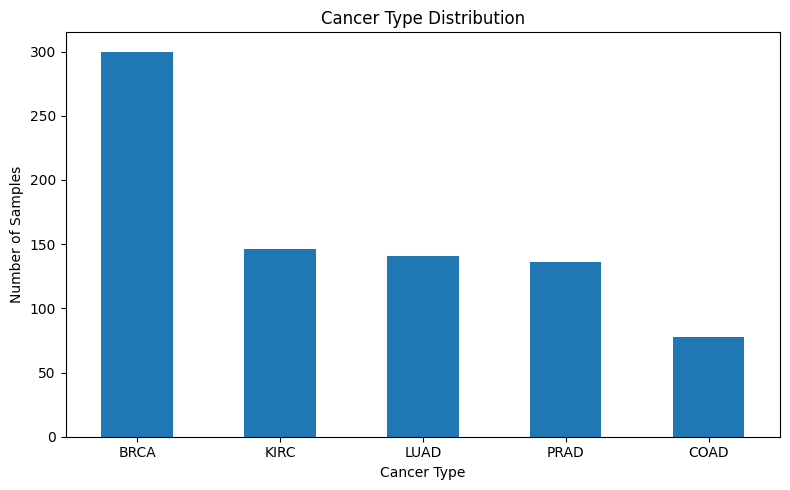

In [23]:
# Count cancer samples
cancer_counts = labels.iloc[:, -1].value_counts()

# Display distribution
display(cancer_counts)

# Visualize distribution
cancer_counts.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

matplotlib.title("Cancer Type Distribution")
matplotlib.xlabel("Cancer Type")
matplotlib.ylabel("Number of Samples")
matplotlib.tight_layout()
matplotlib.show()

###  12 — Gene Expression Distribution

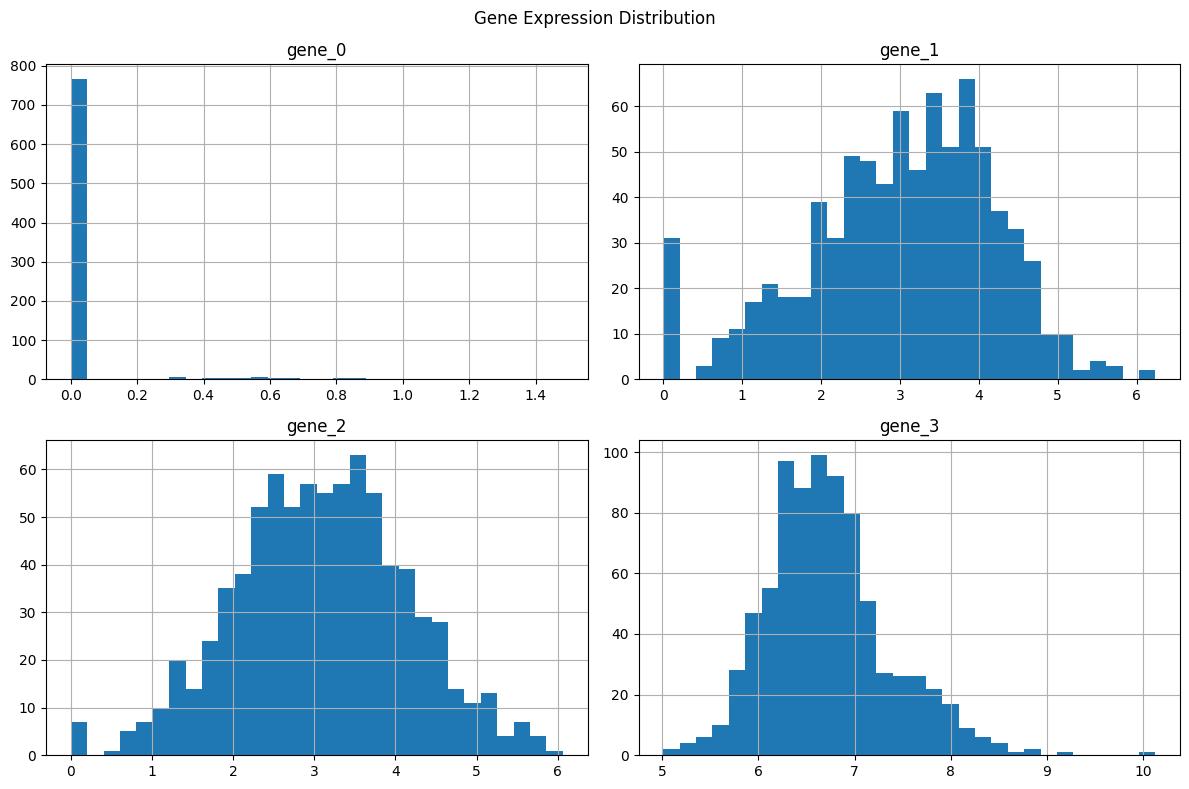

In [31]:
# Select a small number of features for visualization
selected_features = data.iloc[:, :5]

selected_features.hist(
    figsize=(12, 8),
    bins=30
)

matplotlib.suptitle("Gene Expression Distribution")
matplotlib.tight_layout()
matplotlib.show()

### 13 — Correlation Analysis

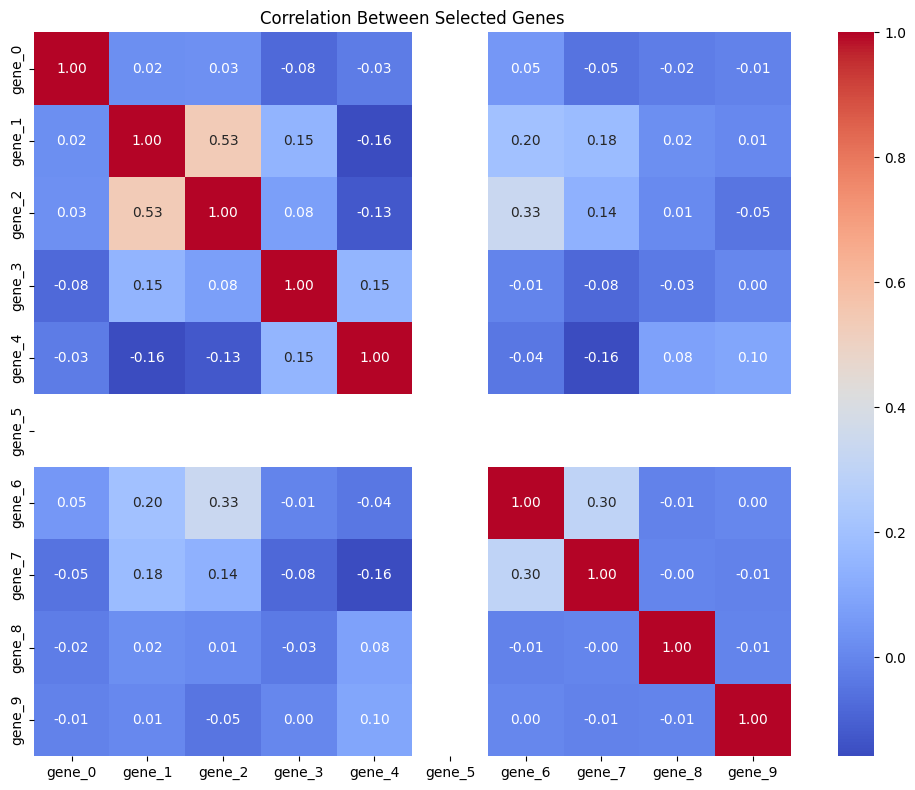

In [30]:
# Calculate correlation between selected genes
correlation = data.select_dtypes(include="number").iloc[:, :10].corr()

matplotlib.figure(figsize=(10, 8))

seaborn.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

matplotlib.title("Correlation Between Selected Genes")
matplotlib.tight_layout()
matplotlib.show()

## Conclusion

In this notebook, we explored the Gene Expression Cancer RNA-Seq dataset.

The exploration included:

- Dataset dimensions.
- Gene expression features.
- Cancer labels.
- Statistical descriptions.
- Missing values and duplicate records.
- Cancer type distribution.
- Gene expression distributions.
- Correlation between selected features.

### Next Step

Prepare the gene expression matrix for Principal Component
Analysis (PCA) to reduce dimensionality and visualize
the relationships between cancer samples.